In [10]:
import zipfile
import os

zip_path = '/content/archive (6) (1).zip'
extract_dir = '/content/extracted_data'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

print("Extracted files:")
for root, dirs, files in os.walk(extract_dir):
    for file in files:
        print(os.path.join(root, file))

Extracted files:
/content/extracted_data/train_cancer/malignant/18.jpg
/content/extracted_data/train_cancer/malignant/69.jpg
/content/extracted_data/train_cancer/malignant/204.jpg
/content/extracted_data/train_cancer/malignant/79.jpg
/content/extracted_data/train_cancer/malignant/250.jpg
/content/extracted_data/train_cancer/malignant/70.jpg
/content/extracted_data/train_cancer/malignant/191.jpg
/content/extracted_data/train_cancer/malignant/234.jpg
/content/extracted_data/train_cancer/malignant/282.jpg
/content/extracted_data/train_cancer/malignant/223.jpg
/content/extracted_data/train_cancer/malignant/35.jpg
/content/extracted_data/train_cancer/malignant/78.jpg
/content/extracted_data/train_cancer/malignant/202.jpg
/content/extracted_data/train_cancer/malignant/285.jpg
/content/extracted_data/train_cancer/malignant/175.jpg
/content/extracted_data/train_cancer/malignant/15.jpg
/content/extracted_data/train_cancer/malignant/53.jpg
/content/extracted_data/train_cancer/malignant/21.jpg
/c

--- Class Distribution ---
label
malignant    240
benign        30
Name: count, dtype: int64

--- Image Dimensions Summary ---
       width  height  aspect_ratio
count  270.0   270.0         270.0
mean   224.0   224.0           1.0
std      0.0     0.0           0.0
min    224.0   224.0           1.0
25%    224.0   224.0           1.0
50%    224.0   224.0           1.0
75%    224.0   224.0           1.0
max    224.0   224.0           1.0


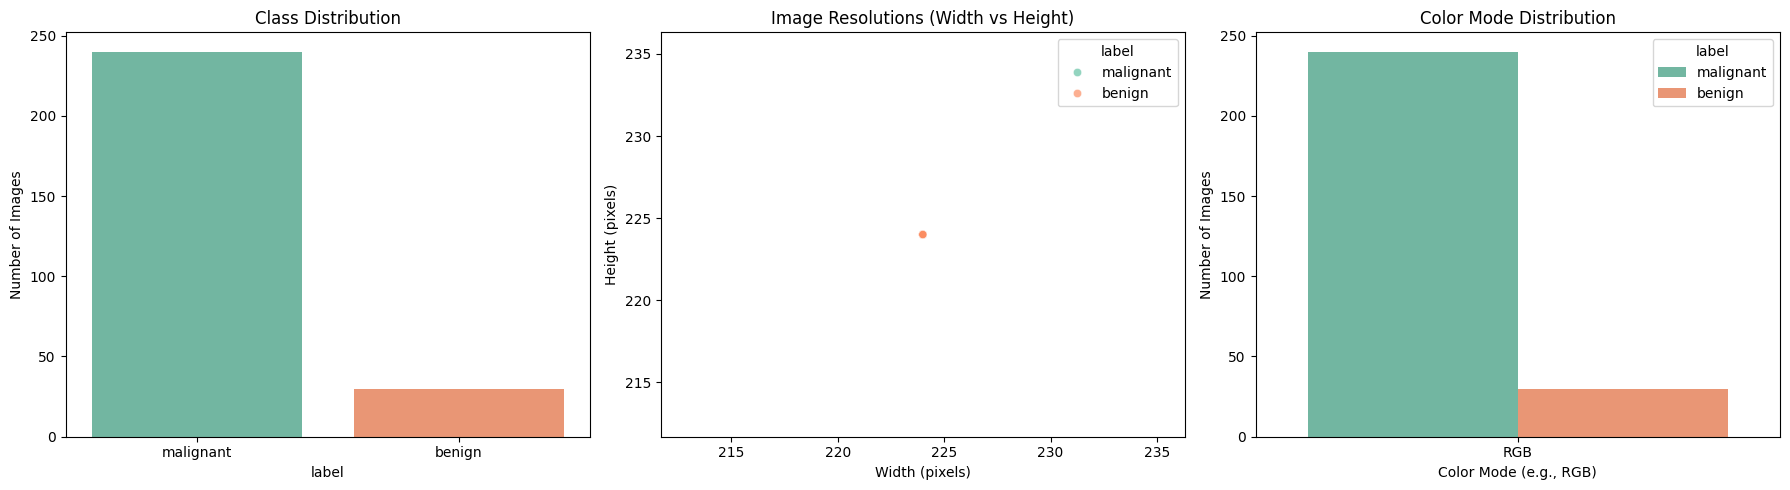

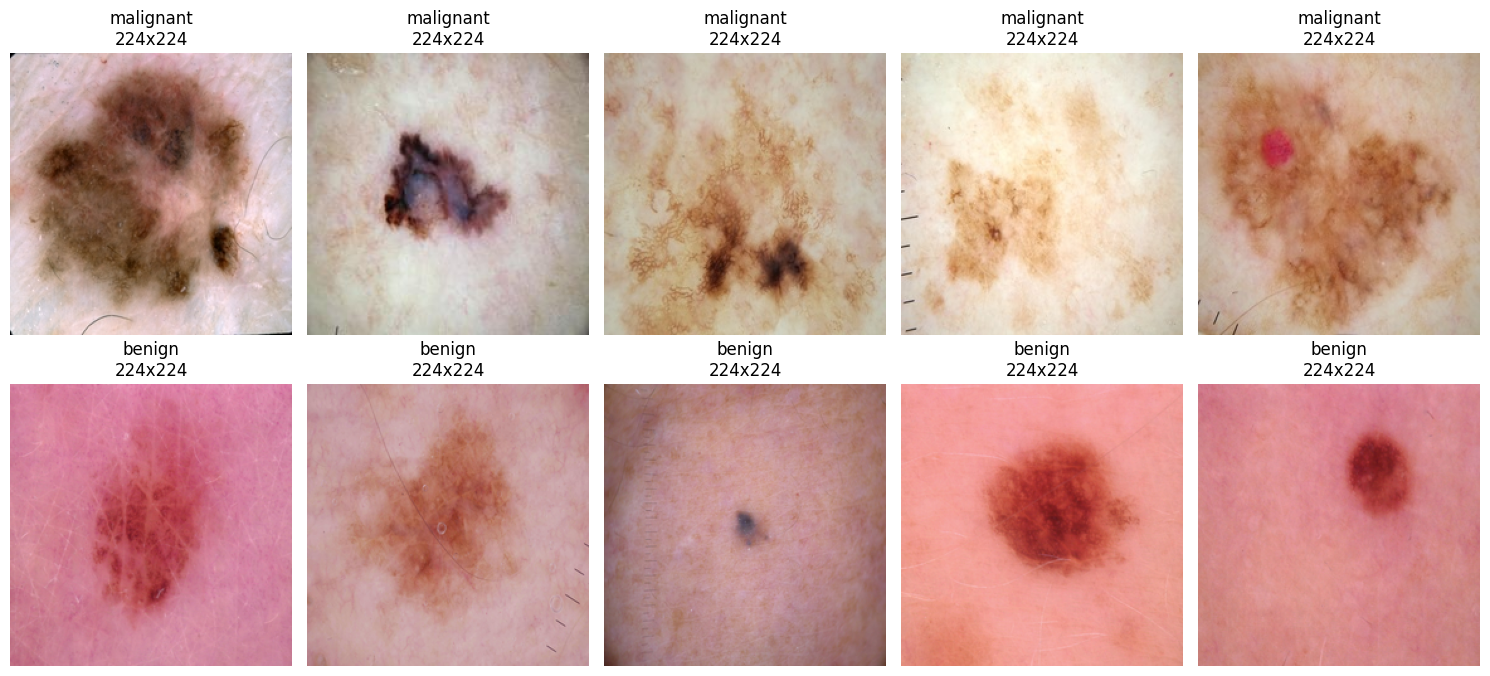

In [11]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Define directories
data_dir = '/content/extracted_data/train_cancer'
classes = ['malignant', 'benign']

# 1. Gather file information
data = []
for c in classes:
    class_path = os.path.join(data_dir, c)
    files = glob.glob(os.path.join(class_path, '*'))
    for f in files:
        try:
            with Image.open(f) as img:
                width, height = img.size
                mode = img.mode
                data.append({
                    'filepath': f,
                    'label': c,
                    'width': width,
                    'height': height,
                    'aspect_ratio': width / height,
                    'mode': mode
                })
        except Exception as e:
            # Handle potential non-image files
            pass

df = pd.DataFrame(data)

# 2. Print distribution & basic statistics
print("--- Class Distribution ---")
print(df['label'].value_counts())
print("\n--- Image Dimensions Summary ---")
print(df[['width', 'height', 'aspect_ratio']].describe())

# 3. Visualize Class Distribution, Image Dimensions & Modes
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Class count plot
sns.countplot(data=df, x='label', hue='label', ax=axes[0], palette='Set2', legend=False)
axes[0].set_title('Class Distribution')
axes[0].set_ylabel('Number of Images')

# Width vs Height scatter plot
sns.scatterplot(data=df, x='width', y='height', hue='label', alpha=0.7, ax=axes[1], palette='Set2')
axes[1].set_title('Image Resolutions (Width vs Height)')
axes[1].set_xlabel('Width (pixels)')
axes[1].set_ylabel('Height (pixels)')

# Color Mode Distribution
sns.countplot(data=df, x='mode', hue='label', ax=axes[2], palette='Set2')
axes[2].set_title('Color Mode Distribution')
axes[2].set_xlabel('Color Mode (e.g., RGB)')
axes[2].set_ylabel('Number of Images')

plt.tight_layout()
plt.show()

# 4. Display Sample Images from each category
fig, axes = plt.subplots(2, 5, figsize=(15, 7))
for i, c in enumerate(classes):
    class_df = df[df['label'] == c].sample(min(5, len(df[df['label'] == c])), random_state=42).reset_index(drop=True)
    for j in range(5):
        ax = axes[i, j]
        if j < len(class_df):
            img_path = class_df.loc[j, 'filepath']
            img = Image.open(img_path)
            ax.imshow(img)
            ax.set_title(f"{c}\n{img.size[0]}x{img.size[1]}")
        ax.axis('off')

plt.tight_layout()
plt.show()

Total dataset size: 270
Training set size: 216 (80.0%)
Testing set size: 54 (20.0%)

--- Train Set Class Distribution ---
label
malignant    192
benign        24
Name: count, dtype: int64

--- Test Set Class Distribution ---
label
malignant    48
benign        6
Name: count, dtype: int64


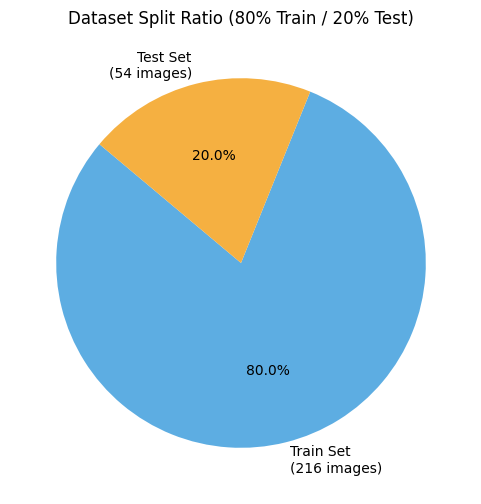

In [12]:
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# Perform stratified 80/20 train/test split to maintain class balance
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df['label']
)

print(f"Total dataset size: {len(df)}")
print(f"Training set size: {len(train_df)} ({len(train_df)/len(df)*100:.1f}%)")
print(f"Testing set size: {len(test_df)} ({len(test_df)/len(df)*100:.1f}%)")

print("\n--- Train Set Class Distribution ---")
print(train_df['label'].value_counts())

print("\n--- Test Set Class Distribution ---")
print(test_df['label'].value_counts())

# Create a pie chart showing the Train/Test Split
split_sizes = [len(train_df), len(test_df)]
split_labels = [f'Train Set\n({len(train_df)} images)', f'Test Set\n({len(test_df)} images)']

plt.figure(figsize=(6, 6))
plt.pie(split_sizes, labels=split_labels, autopct='%1.1f%%', startangle=140, colors=['#5dade2', '#f5b041'])
plt.title('Dataset Split Ratio (80% Train / 20% Test)')
plt.show()

In [13]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# 1. Define image parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 16

# 2. Data Augmentation & Generators using the split DataFrames
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='filepath',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=True,
    seed=42
)

test_generator = test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col='filepath',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

Found 216 validated image filenames belonging to 2 classes.
Found 54 validated image filenames belonging to 2 classes.


In [14]:
# 3. Build a CNN Model
model = models.Sequential([
    # Convolutional Block 1
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)),
    layers.MaxPooling2D((2, 2)),

    # Convolutional Block 2
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Convolutional Block 3
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Flatten and Dense Layers
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    # Binary classification output (sigmoid activation)
    layers.Dense(1, activation='sigmoid')
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# 4. Train the Model
EPOCHS = 15

history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=test_generator
)

Epoch 1/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 34s 2s/step - accuracy: 0.8102 - loss: 1.0265 - precision_1: 0.8794 - recall_1: 0.9115 - val_accuracy: 0.8889 - val_loss: 0.3579 - val_precision_1: 0.8889 - val_recall_1: 1.0000
Epoch 2/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 35s 2s/step - accuracy: 0.8889 - loss: 0.3971 - precision_1: 0.8889 - recall_1: 1.0000 - val_accuracy: 0.8889 - val_loss: 0.4551 - val_precision_1: 0.8889 - val_recall_1: 1.0000
Epoch 3/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 31s 2s/step - accuracy: 0.8889 - loss: 0.3510 - precision_1: 0.8889 - recall_1: 1.0000 - val_accuracy: 0.8889 - val_loss: 0.3323 - val_precision_1: 0.8889 - val_recall_1: 1.0000
Epoch 4/15
 7/14 ━━━━━━━━━━━━━━━━━━━━ 15s 2s/step - accuracy: 0.9497 - loss: 0.1801 - precision_1: 0.9497 - recall_1: 1.0000

In [ ]:
# 5. Visualize Training Results
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot accuracy
axes[0].plot(history.history['accuracy'], label='Train Accuracy', color='b')
axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy', color='r')
axes[0].set_title('Training vs Validation Accuracy')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

# Plot loss
axes[1].plot(history.history['loss'], label='Train Loss', color='b')
axes[1].plot(history.history['val_loss'], label='Validation Loss', color='r')
axes[1].set_title('Training vs Validation Loss')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Loss')
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
# Evaluate the model on the test generator
eval_results = model.evaluate(test_generator)

# Map metrics based on model.compile configurations
loss = eval_results[0]
accuracy = eval_results[1]
precision = eval_results[2]
recall = eval_results[3]

print("\n--- Model Test Evaluation Results ---")
print(f"Loss: {loss:.4f}")
print(f"Accuracy: {accuracy * 100:.2f}%")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")

# Check if accuracy meets the 80% threshold
if accuracy >= 0.80:
    print("\nSuccess! The model accuracy is at least 80%.")
else:
    print("\nThe model accuracy is below 80%. We might need more training or parameter tuning.")

# Save the model to disk
model_save_path = '/content/malignant_benign_cnn_model.keras'
model.save(model_save_path)
print(f"\nModel successfully saved to {model_save_path}")